<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week3/lesson11/Lesson11_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 11 — Critical Points and Curvature: Valleys, Peaks and Flat Directions

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 3 — Calculus I\
**Lesson:** Lesson 11\
**Notebook type:** Teaching notebook

> *"Fitting a model means finding the bottom of a valley. Whether the valley has one bottom or many, and whether it is a narrow gorge or a wide flat plain, decides what the fit can tell you."*

---

### Where the slope is zero

Lessons 9 and 10 computed slopes: how fast a function, or a loss, changes. This lesson looks at the special places where the slope is **zero**, the **critical points**: bottoms of valleys (minima), tops of hills (maxima), and flat ledges in between. Fitting any model (Lessons 5, 8, 10) is a search for the lowest point of a loss function, so critical points are where fitting ends.

The **second derivative** tells critical points apart and measures **curvature**: how sharply the function bends. Curvature underlies the quadratic (Taylor) approximation, decides whether a loss is **convex** (one valley) or not, and distinguishes **sharp** directions, where parameters are tightly determined by the data, from **flat** ones, where parameters can trade off against each other almost for free. The mini-lab examines the loss landscape of the speed-tuning model fitted in Lesson 8 to a motor-cortex neuron, and asks what its curvature says about how well each parameter is known.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-10.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-10.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def central_diff(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

def second_diff(f, x, h=1e-4):
    # Central second difference: (f(x+h) - 2 f(x) + f(x-h)) / h^2  (Part 2).
    return (f(x + h) - 2 * f(x) + f(x - h)) / h**2

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: a landscape with two valleys**

Many models in neuroscience describe a system settling into the lowest point of an "energy" landscape. A memory network that can hold one of two states, a decision circuit choosing between two options, a neuron with two stable membrane potentials: each can be pictured as a ball rolling downhill on a curve with **two valleys**,

$$E(x) = x^4 - 2x^2 + 0.3x .$$

The state $x$ (the activity of the circuit, say) always moves downhill: $\Delta x \propto -E'(x)$. Where it ends up depends on where it starts.

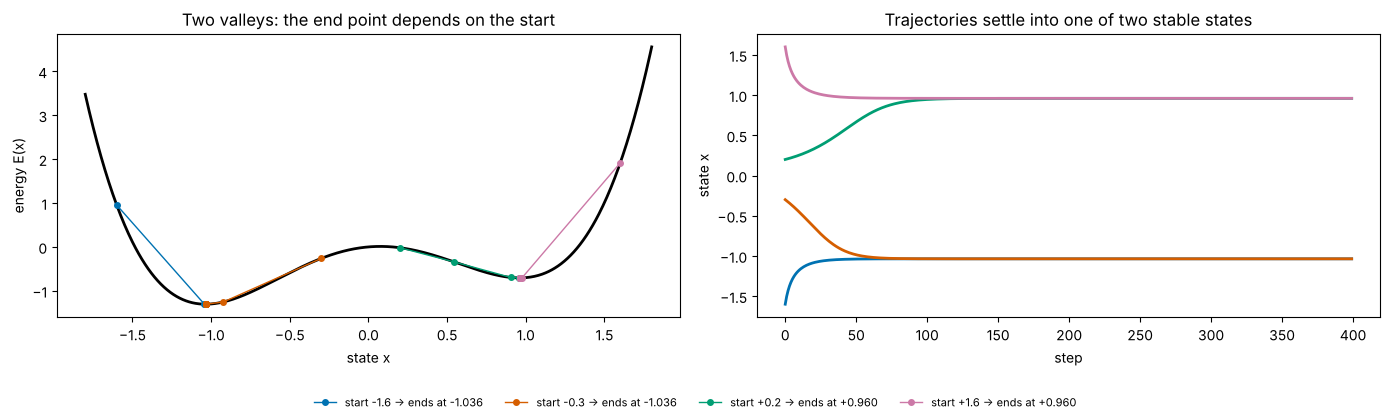

points where E'(x) = 0: [-1.0356  0.0754  0.9601]


In [3]:
def E(x):
    return x**4 - 2 * x**2 + 0.3 * x
def dE(x):
    return 4 * x**3 - 4 * x + 0.3

def roll_downhill(x0, step=0.01, n_steps=2000):
    # Follow the slope downhill: x <- x - step * E'(x). (Lesson 12 studies this rule.)
    xs = [x0]
    for _ in range(n_steps):
        xs.append(xs[-1] - step * dE(xs[-1]))
    return np.array(xs)

x = np.linspace(-1.8, 1.8, 721)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(x, E(x), color='black', lw=2)
for x0, colour in zip([-1.6, -0.3, 0.2, 1.6], PALETTE):
    path = roll_downhill(x0)
    axes[0].plot(path[::40], E(path[::40]), 'o-', ms=4, color=colour, lw=1, label=f'start {x0:+.1f} -> ends at {path[-1]:+.3f}')
axes[0].set_xlabel('state x'); axes[0].set_ylabel('energy E(x)'); axes[0].set_title('Two valleys: the end point depends on the start')
for x0, colour in zip([-1.6, -0.3, 0.2, 1.6], PALETTE):
    axes[1].plot(roll_downhill(x0)[:400], color=colour, lw=2)
axes[1].set_xlabel('step'); axes[1].set_ylabel('state x'); axes[1].set_title('Trajectories settle into one of two stable states')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()
crit = np.sort(np.roots([4, 0, -4, 0.3]).real)
print("points where E'(x) = 0:", np.round(crit, 4))

The slope $E'(x)$ is zero at three points. Two are valley bottoms, where the ball comes to rest and stays (**stable**); one is a hilltop between them, where a ball could balance in principle but any nudge sends it into one valley or the other (**unstable**). The two valleys are not equally deep: the left one is the **global** minimum, the right one only a **local** minimum, and a ball that starts on the right never finds out that a lower valley exists. This lesson gives the tools to find, classify and characterise such points.

# **Part 1: Critical Points and Sign Changes of the Derivative**

A **critical point** of a differentiable function is a point where $f'(x) = 0$: the tangent is horizontal. The **first-derivative test** classifies it by how the sign of $f'$ changes as $x$ passes through it:

| Sign of $f'$, left → right | Shape | Type |
|---|---|---|
| $-$ → $+$ | falls, then rises | **local minimum** |
| $+$ → $-$ | rises, then falls | **local maximum** |
| no change ($+$→$+$ or $-$→$-$) | pauses, then continues | neither (a **stationary inflection**, e.g. $x^3$ at 0) |

A **global** minimum is the lowest value over the whole domain. On a bounded domain $[a, b]$ it may sit at an **endpoint**, where $f'$ need not be zero, so endpoints must be checked too. Points where $f'$ does not exist (ReLU's corner, $|x|$ at 0) can also be minima or maxima.

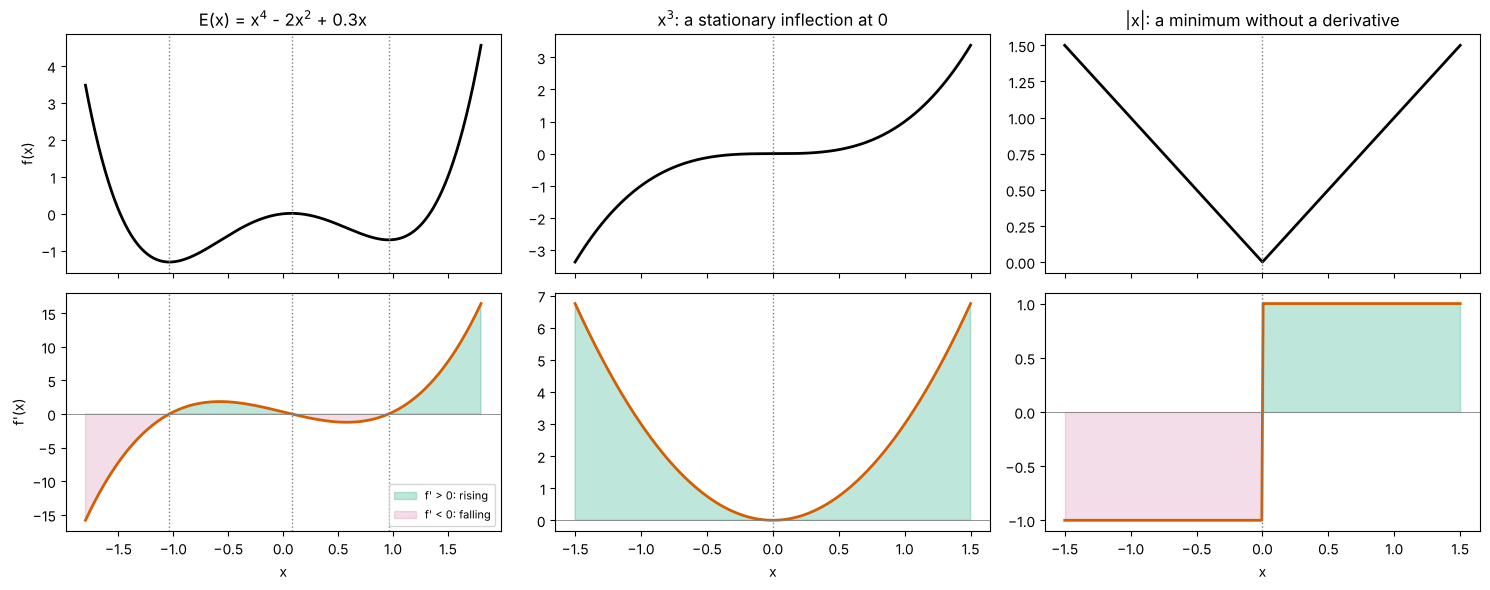

x = -1.0356: E'(left) = -0.0089, E'(right) = +0.0089  ->  local minimum, E = -1.3054
x = +0.0754: E'(left) = +0.0039, E'(right) = -0.0039  ->  local maximum, E = +0.0113
x = +0.9601: E'(left) = -0.0071, E'(right) = +0.0071  ->  local minimum, E = -0.7059


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex='col')
examples = [('E(x) = x$^4$ - 2x$^2$ + 0.3x', E, dE, np.linspace(-1.8, 1.8, 721)),
            ('x$^3$: a stationary inflection at 0', lambda t: t**3, lambda t: 3 * t**2, np.linspace(-1.5, 1.5, 601)),
            ('|x|: a minimum without a derivative', np.abs, lambda t: np.sign(t), np.linspace(-1.5, 1.5, 601))]
for col, (title, f, df, xs) in enumerate(examples):
    axes[0, col].plot(xs, f(xs), color='black', lw=2); axes[0, col].set_title(title)
    d = df(xs)
    axes[1, col].plot(xs, d, color=PALETTE[1], lw=2)
    axes[1, col].fill_between(xs, 0, d, where=d > 0, color=PALETTE[2], alpha=0.25, label="f' > 0: rising")
    axes[1, col].fill_between(xs, 0, d, where=d < 0, color=PALETTE[3], alpha=0.25, label="f' < 0: falling")
    axes[1, col].axhline(0, color='grey', lw=0.6); axes[1, col].set_xlabel('x')
    for xc in [c_ for c_ in (np.sort(np.roots([4, 0, -4, 0.3]).real) if col == 0 else [0.0])]:
        for ax in axes[:, col]:
            ax.axvline(xc, color='grey', ls=':', lw=1)
axes[0, 0].set_ylabel('f(x)'); axes[1, 0].set_ylabel("f'(x)"); axes[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

for xc in crit:
    left, right = dE(xc - 1e-3), dE(xc + 1e-3)
    kind = 'local minimum' if left < 0 < right else ('local maximum' if left > 0 > right else 'neither')
    print(f"x = {xc:+.4f}: E'(left) = {left:+.4f}, E'(right) = {right:+.4f}  ->  {kind}, E = {E(xc):+.4f}")

### Finding critical points numerically

For a polynomial, `np.roots` finds all zeros of $f'$ at once. In general, $f'(x) = 0$ is an equation solved by **bisection** (Lesson 8) on any interval where $f'$ changes sign, or by Newton's method (Part 3). A practical approach for a function of one variable: evaluate $f'$ on a fine grid, find where its sign changes, and refine each change by bisection. As always, the grid must be fine enough not to miss a pair of nearby critical points (Lesson 8's sampling pitfalls).

# **Part 2: The Second Derivative and Curvature**

The **second derivative** $f''(x)$ is the derivative of $f'$: how fast the slope itself changes. Its sign says which way the graph bends:

- $f''(x) > 0$: the slope is increasing; the graph bends **upwards** (**convex**, "holds water");
- $f''(x) < 0$: the slope is decreasing; the graph bends **downwards** (**concave**);
- where $f''$ changes sign, the graph has an **inflection point**.

**Second-derivative test.** At a critical point ($f'(x^*) = 0$): if $f''(x^*) > 0$ it is a local minimum; if $f''(x^*) < 0$, a local maximum; if $f''(x^*) = 0$ the test is inconclusive (go back to sign changes).

**Units.** $f''$ has the units of the output per unit of input **squared**: acceleration (cm/s$^2$) is the second derivative of position; a loss's second derivative with respect to a parameter has units of loss per (parameter unit)$^2$.

Numerically, $f''(x) \approx \frac{f(x + h) - 2f(x) + f(x - h)}{h^2}$ (a difference of differences). It divides by $h^2$, so it is even more sensitive to rounding and noise than a first difference (Lesson 9).

x = -1.0356: E''(x) = +8.869 (numerical +8.869)  ->  minimum
x = +0.0754: E''(x) = -3.932 (numerical -3.932)  ->  maximum
x = +0.9601: E''(x) = +7.063 (numerical +7.063)  ->  minimum
inflection points (E'' = 0): x = [-0.5774  0.5774]


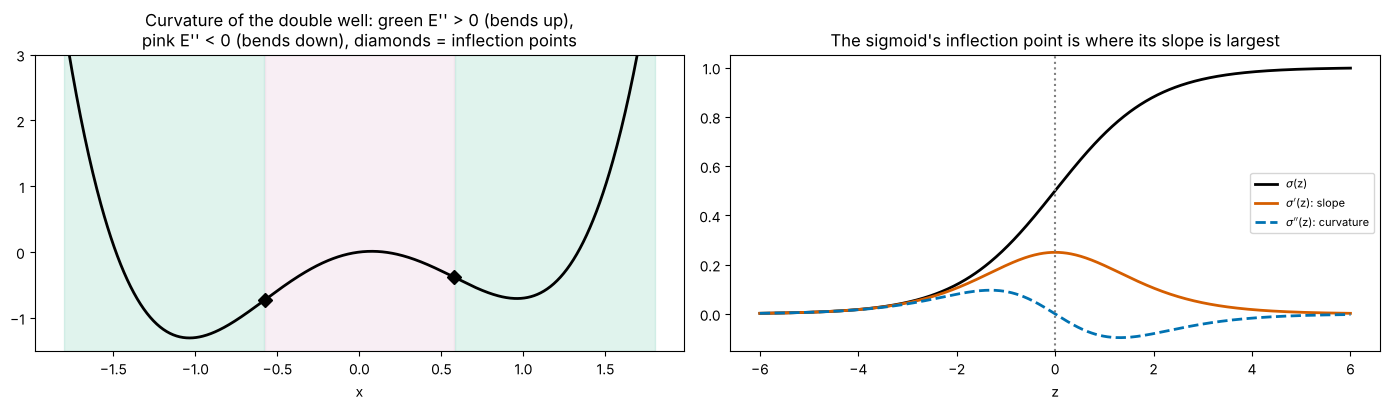

In [5]:
def d2E(x):
    return 12 * x**2 - 4

for xc in crit:
    print(f"x = {xc:+.4f}: E''(x) = {d2E(xc):+.3f} (numerical {second_diff(E, xc):+.3f})  ->  {'minimum' if d2E(xc) > 0 else 'maximum'}")
x_infl = np.array([-1, 1]) / np.sqrt(3)
print(f"inflection points (E'' = 0): x = {np.round(x_infl, 4)}")

sig = lambda t: 1 / (1 + np.exp(-t))
ts = np.linspace(-6, 6, 601)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(x, E(x), color='black', lw=2, label='E(x)')
axes[0].fill_between(x, E(x).min() - 0.2, E(x).max(), where=d2E(x) > 0, color=PALETTE[2], alpha=0.12, label="E'' > 0: bends up (convex)")
axes[0].fill_between(x, E(x).min() - 0.2, E(x).max(), where=d2E(x) < 0, color=PALETTE[3], alpha=0.12, label="E'' < 0: bends down (concave)")
axes[0].plot(x_infl, E(x_infl), 'kD', ms=7, label='inflection points')
axes[0].set_ylim(E(x).min() - 0.2, 3); axes[0].set_xlabel('x'); axes[0].set_title("Curvature of the double well: green E'' > 0 (bends up),\npink E'' < 0 (bends down), diamonds = inflection points")
s_ = sig(ts)
axes[1].plot(ts, s_, color='black', lw=2, label='$\\sigma$(z)')
axes[1].plot(ts, s_ * (1 - s_), color=PALETTE[1], lw=2, label="$\\sigma'$(z): slope")
axes[1].plot(ts, s_ * (1 - s_) * (1 - 2 * s_), color=PALETTE[0], lw=2, ls='--', label="$\\sigma''$(z): curvature")
axes[1].axvline(0, color='grey', ls=':')
axes[1].set_xlabel('z'); axes[1].set_title("The sigmoid's inflection point is where its slope is largest"); axes[1].legend(fontsize=8, loc='center right')
plt.tight_layout(); plt.show()

The right panel links Lessons 9 and 11. The **steepest** point of a curve, where $f'$ is largest, is a critical point **of $f'$**, so there $f'' = 0$: an inflection point. The sigmoid's inflection point at $z = 0$ is where a sigmoidal neuron is most sensitive (Lesson 9) and where its gradient is largest (Lesson 10).

# **Part 3: Taylor Approximation — Curvature in the Local Picture**

Lesson 9's linear approximation used the slope. Adding curvature gives the **quadratic** (second-order Taylor) approximation:

$$f(x + h) \approx f(x) + f'(x)\,h + \tfrac12 f''(x)\,h^2 .$$

More terms give better approximations near $x$, the **Taylor polynomial** of order $n$:

$$f(x + h) \approx \sum_{k=0}^{n}\frac{f^{(k)}(x)}{k!}\,h^k ,$$

with an error that shrinks like $h^{n+1}$ for small $h$. Near a **minimum** $x^*$, where $f'(x^*) = 0$, the quadratic approximation becomes

$$f(x) \approx f(x^*) + \tfrac12 f''(x^*)\,(x - x^*)^2 :$$

**every smooth valley looks like a parabola near its bottom**, and its width is set by $f''(x^*)$. A large $f''$ is a narrow, sharp valley; a small $f''$ is a wide, flat one.

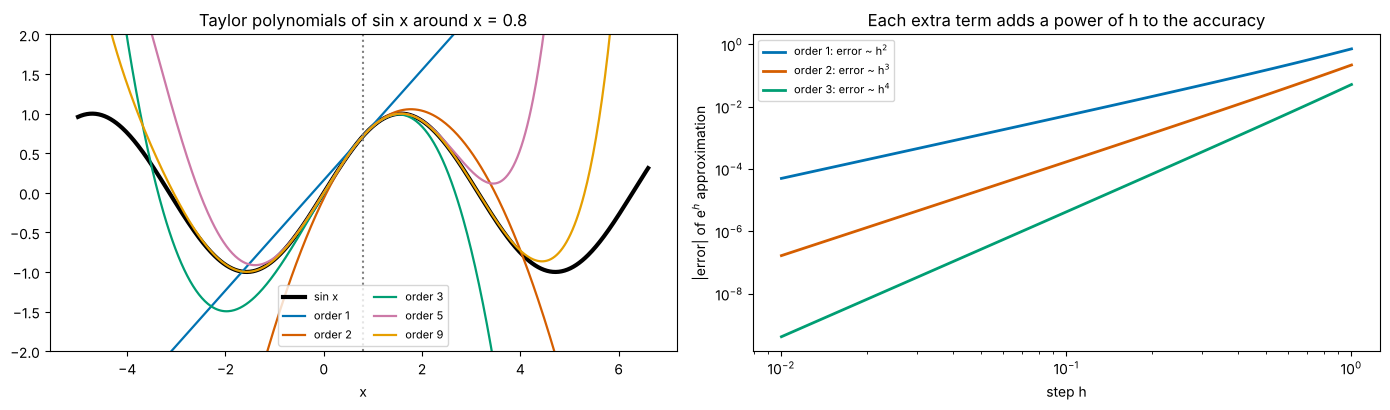

valley at -1.036: E'' = 8.87; the parabola rises by 0.1 at a distance 0.150 from the bottom
valley at +0.960: E'' = 7.06; the parabola rises by 0.1 at a distance 0.168 from the bottom


In [6]:
from math import factorial
x0_t = 0.8                      # expansion point; not 0, where sin'' = 0 would make orders 1 and 2 identical
orders = [1, 2, 3, 5, 9]
xs_t = np.linspace(-5, 6.6, 581)
def taylor_sin(xs, n, a=x0_t):
    # Taylor polynomial of sin around a: derivatives cycle sin a, cos a, -sin a, -cos a.
    cyc = [np.sin(a), np.cos(a), -np.sin(a), -np.cos(a)]
    return sum(cyc[k % 4] / factorial(k) * (xs - a)**k for k in range(n + 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(xs_t, np.sin(xs_t), color='black', lw=3, label='sin x')
for n_, colour in zip(orders, PALETTE):
    axes[0].plot(xs_t, taylor_sin(xs_t, n_), color=colour, lw=1.6, label=f'order {n_}')
axes[0].axvline(x0_t, color='grey', ls=':'); axes[0].set_ylim(-2, 2); axes[0].set_xlabel('x'); axes[0].set_title(f'Taylor polynomials of sin x around x = {x0_t}'); axes[0].legend(fontsize=8, ncol=2)
hs = np.logspace(-2, 0, 30)
for n_, colour in zip([1, 2, 3], PALETTE):
    err = np.abs(np.exp(hs) - sum(hs**k / factorial(k) for k in range(n_ + 1)))
    axes[1].loglog(hs, err, color=colour, lw=2, label=f'order {n_}: error ~ h$^{n_ + 1}$')
axes[1].set_xlabel('step h'); axes[1].set_ylabel('|error| of e$^h$ approximation'); axes[1].set_title('Each extra term adds a power of h to the accuracy'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

for xc in crit[[0, 2]]:
    print(f"valley at {xc:+.3f}: E'' = {d2E(xc):.2f}; the parabola rises by 0.1 at a distance {np.sqrt(0.2 / d2E(xc)):.3f} from the bottom")

#### Interactive version: add terms one at a time

In [7]:
orders_all = list(range(0, 16))
fig_t = go.Figure([go.Scatter(x=xs_t, y=np.round(np.sin(xs_t), 4), mode='lines', line=dict(color='black', width=4), name='sin x'),
                   go.Scatter(x=xs_t, y=np.round(taylor_sin(xs_t, 0), 4), mode='lines', line=dict(color=PALETTE[1], width=3), name='Taylor polynomial')])
fig_t.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(y=np.round(np.clip(taylor_sin(xs_t, n_), -5, 5), 4))],
                         layout=go.Layout(title=f'Taylor polynomial of order {n_} around x = {x0_t}')) for k, n_ in enumerate(orders_all)]
buttons, sliders = play_pause_and_slider(orders_all, prefix='order = ', duration=500)
fig_t.update_layout(title=fig_t.frames[0].layout.title.text, xaxis_title='x', yaxis=dict(range=[-2, 2], title='value'), template='plotly_white',
                    width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_t.show(config=PLOTLY_CONFIG)

### Newton's method: jump to the bottom of the parabola

If a valley looks like a parabola, jump straight to the parabola's minimum. Setting the derivative of $f(x) + f'(x)h + \frac12 f''(x)h^2$ with respect to $h$ to zero gives $h = -f'(x)/f''(x)$, so **Newton's method** iterates

$$x \leftarrow x - \frac{f'(x)}{f''(x)} .$$

Near a minimum it converges extremely fast (the number of correct digits roughly doubles each step), but it heads for **any** critical point, including maxima, and fails where $f''$ is near zero. Lesson 12's gradient descent uses only $f'$, taking smaller, safer steps.

In [8]:
for x_start in [1.5, 0.3, -0.05]:
    xk = x_start; path = [xk]
    for _ in range(6):
        xk = xk - dE(xk) / d2E(xk); path.append(xk)
    end_kind = 'minimum' if d2E(xk) > 0 else 'MAXIMUM'
    print(f"Newton from {x_start:+.2f}: " + ' -> '.join(f'{p:+.6f}' for p in path) + f"   ({end_kind})")

Newton from +1.50: +1.500000 -> +1.160870 -> +1.003603 -> +0.962921 -> +0.960162 -> +0.960150 -> +0.960150   (minimum)
Newton from +0.30: +0.300000 -> +0.028767 -> +0.075139 -> +0.075429 -> +0.075429 -> +0.075429 -> +0.075429   (MAXIMUM)
Newton from -0.05: -0.050000 -> +0.075819 -> +0.075429 -> +0.075429 -> +0.075429 -> +0.075429 -> +0.075429   (MAXIMUM)


# **Part 4: Convex and Non-Convex Objectives — Local and Global Minima**

A function is **convex** if the straight line (chord) between any two points of its graph lies on or above the graph. For a twice-differentiable function of one variable this is the same as $f''(x) \ge 0$ everywhere. Convex functions have a decisive property:

> **Every local minimum of a convex function is a global minimum.** If the function is strictly convex ($f'' > 0$), there is at most one minimum.

So for a convex loss, "find a point where the slope is zero" is the whole job, and any downhill method that stops will stop at the right answer. **Least squares** (Lesson 5) is convex in the coefficients, as is the logistic-regression loss and the Poisson loss of Lesson 10's exercise. That is why those fits are reliable.

**Non-convex** losses can have several local minima, plateaus and saddles. Neural networks (Lesson 10), most models with nonlinear parameters (the saturating speed model of Lesson 8, a tuning curve's preferred direction), and energy landscapes like the double well are non-convex. A downhill method then finds **a** local minimum that depends on where it started, and the only general defence is to start from many places and compare.

**Convexity depends on the parameterisation.** A cosine tuning curve $r = b + a\cos(\theta - \theta_{\text{pref}})$ is non-convex in $\theta_{\text{pref}}$. Rewritten as $r = b + c_1\cos\theta + c_2\sin\theta$ (since $a\cos(\theta - \theta_p) = a\cos\theta_p\cos\theta + a\sin\theta_p\sin\theta$), it is **linear** in $(b, c_1, c_2)$, and least squares in those is convex with a unique answer. Lessons 2 and 4 did exactly this.

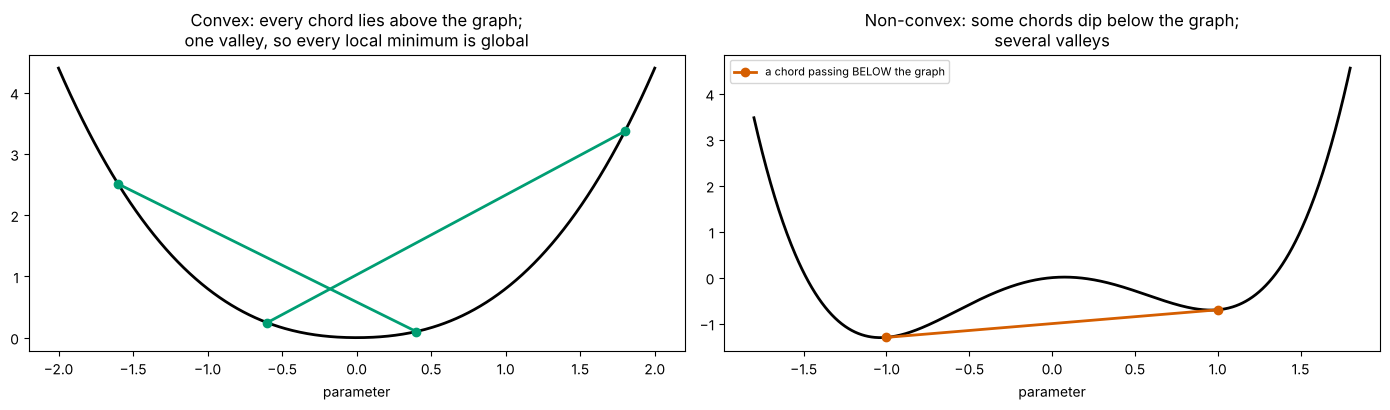

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
xx = np.linspace(-2, 2, 401)
conv = lambda t: 0.5 * t**2 + 0.3 * np.abs(t)**3
axes[0].plot(xx, conv(xx), color='black', lw=2)
for a_, b_ in [(-1.6, 0.4), (-0.6, 1.8)]:
    axes[0].plot([a_, b_], [conv(a_), conv(b_)], 'o-', color=PALETTE[2], lw=2)
axes[0].set_title('Convex: every chord lies above the graph;\none valley, so every local minimum is global'); axes[0].set_xlabel('parameter')
axes[1].plot(x, E(x), color='black', lw=2)
for a_, b_ in [(-1.0, 1.0)]:
    axes[1].plot([a_, b_], [E(a_), E(b_)], 'o-', color=PALETTE[1], lw=2, label='a chord passing BELOW the graph')
axes[1].set_title('Non-convex: some chords dip below the graph;\nseveral valleys'); axes[1].set_xlabel('parameter'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Interactive version: where does downhill lead?

Drag the starting point. Each frame follows the downhill rule from that start on the double well.

In [10]:
starts = np.round(np.linspace(-1.7, 1.7, 18), 2)
fig_dw = go.Figure([go.Scatter(x=x, y=np.round(E(x), 4), mode='lines', line=dict(color='black', width=3), name='E(x)'),
                    go.Scatter(x=roll_downhill(starts[0])[::25], y=E(roll_downhill(starts[0])[::25]), mode='lines+markers', marker=dict(size=6, color=PALETTE[1]), name='downhill path')])
fig_dw.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=np.round(roll_downhill(s0_)[::25], 4), y=np.round(E(roll_downhill(s0_)[::25]), 4))],
                          layout=go.Layout(title=f'start {s0_:+.2f}  ->  ends at {roll_downhill(s0_)[-1]:+.3f} ({"global" if roll_downhill(s0_)[-1] < 0 else "local"} minimum)'))
                 for k, s0_ in enumerate(starts)]
buttons, sliders = play_pause_and_slider(list(starts), prefix='start = ', duration=500)
fig_dw.update_layout(title=fig_dw.frames[0].layout.title.text, xaxis_title='x', yaxis=dict(range=[-1.5, 3], title='E(x)'), template='plotly_white',
                     width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_dw.show(config=PLOTLY_CONFIG)

# **Part 5: Flat and Sharp Directions, Parameter Trade-offs and Regularisation**

With two parameters, a loss is a **surface** over the parameter plane, drawn as a contour map (Lesson 14 develops multivariable calculus properly). Near a minimum, the quadratic approximation becomes

$$L(\boldsymbol\theta) \approx L(\boldsymbol\theta^*) + \tfrac12(\boldsymbol\theta - \boldsymbol\theta^*)^{\mathsf T}\mathbf{H}\,(\boldsymbol\theta - \boldsymbol\theta^*),$$

where the **Hessian** $\mathbf{H}$ is the symmetric matrix of second derivatives, $H_{ij} = \partial^2L/\partial\theta_i\partial\theta_j$. By Lesson 6, its eigenvectors are perpendicular directions in parameter space and its eigenvalues are the **curvatures** along them. The contours near the minimum are ellipses whose long axes point along the **flattest** direction.

- **Sharp direction** (large eigenvalue): moving the parameters this way quickly increases the loss, so the data pin this combination down.
- **Flat direction** (small eigenvalue): the loss hardly changes, so this combination is poorly determined. The parameters can **trade off** against each other with little cost.
- The ratio of largest to smallest curvature is the **condition number** (Lesson 5), and it also makes downhill methods slow (Lesson 15).

**A classic trade-off.** Two nearly identical regressors (Lesson 5's collinearity): a neuron's rate modelled from two inputs that are 99% correlated. Increasing one weight while decreasing the other leaves the predictions almost unchanged: a long flat valley.

**Regularisation.** Adding a penalty $\frac{\lambda}{2}\lVert\boldsymbol\theta\rVert^2$ to the loss (**ridge**, Lesson 15) adds $\lambda$ to every curvature (the Hessian becomes $\mathbf{H} + \lambda\mathbf{I}$, whose eigenvalues are the old ones plus $\lambda$, Lesson 6). The flat direction sharpens, the minimum becomes well defined, and the estimate moves towards smaller, more balanced weights. The price is a small bias.

Hessian eigenvalues [0.0102 1.7302] (condition number 169);  flat direction [-0.71   0.705]
lambda = 0.0 : weights [2.844 0.076], curvatures [0.01 1.73], condition number 169.1
lambda = 0.05: weights [1.646 1.184], curvatures [0.06 1.78], condition number 29.6
lambda = 0.3 : weights [1.282 1.199], curvatures [0.31 2.03], condition number 6.5


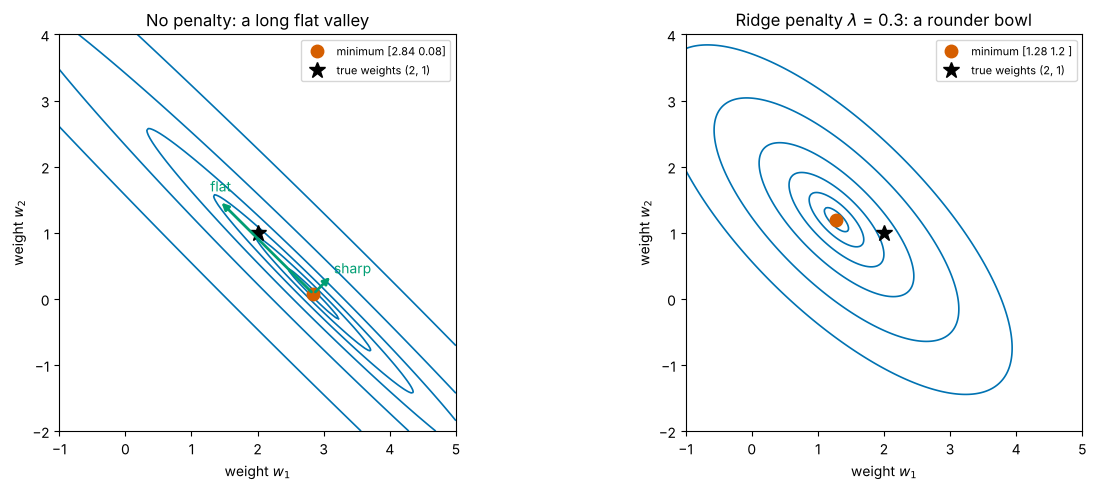

In [11]:
n_r = 300
u1 = RNG.normal(size=n_r)
u2 = 0.99 * u1 + np.sqrt(1 - 0.99**2) * RNG.normal(size=n_r)       # two inputs with correlation 0.99
rate_r = 2.0 * u1 + 1.0 * u2 + RNG.normal(0, 1.0, n_r)                # true weights (2, 1)
Xr = np.column_stack([u1, u2])

def loss_r(w1, w2, lam=0.0):
    resid = rate_r[:, None, None] - (w1 * u1[:, None, None] + w2 * u2[:, None, None])
    return 0.5 * np.mean(resid**2, axis=0) + 0.5 * lam * (w1**2 + w2**2)

H_r = Xr.T @ Xr / n_r                                                 # Hessian of the mean squared loss (exactly, since it is quadratic)
evals, evecs = np.linalg.eigh(H_r)
print(f"Hessian eigenvalues {np.round(evals, 4)} (condition number {evals[1] / evals[0]:.0f});  flat direction {np.round(evecs[:, 0], 3)}")
w_ls = np.linalg.solve(H_r, Xr.T @ rate_r / n_r)
for lam in [0.0, 0.05, 0.3]:
    w_lam = np.linalg.solve(H_r + lam * np.eye(2), Xr.T @ rate_r / n_r)
    ev = evals + lam
    print(f"lambda = {lam:<4}: weights {np.round(w_lam, 3)}, curvatures {np.round(ev, 3)}, condition number {ev[1] / ev[0]:.1f}")

W1, W2 = np.meshgrid(np.linspace(-1, 5, 241), np.linspace(-2, 4, 241))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, lam in zip(axes, [0.0, 0.3]):
    Lgrid = loss_r(W1, W2, lam)
    ax.contour(W1, W2, Lgrid, levels=np.quantile(Lgrid, [0.002, 0.01, 0.03, 0.08, 0.2, 0.4]), colors=[PALETTE[0]], linewidths=1.2)
    w_opt = np.linalg.solve(H_r + lam * np.eye(2), Xr.T @ rate_r / n_r)
    ax.plot(*w_opt, 'o', color=PALETTE[1], ms=9, label=f'minimum {np.round(w_opt, 2)}')
    ax.plot(2, 1, 'k*', ms=12, label='true weights (2, 1)')
    if lam == 0:
        for k_, lab in [(0, 'flat'), (1, 'sharp')]:
            v = evecs[:, k_] * (2.0 if k_ == 0 else 0.4)
            ax.annotate('', xy=w_opt + v, xytext=w_opt, arrowprops=dict(arrowstyle='-|>', color=PALETTE[2], lw=2))
            ax.text(*(w_opt + v * 1.1), lab, color=PALETTE[2])
    ax.set_aspect('equal'); ax.set_xlabel('weight $w_1$'); ax.set_ylabel('weight $w_2$')
    ax.set_title('No penalty: a long flat valley' if lam == 0 else 'Ridge penalty $\\lambda$ = 0.3: a rounder bowl'); ax.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

Without the penalty, the valley is about 170 times flatter along $(1, -1)/\sqrt2$, "more of one input, less of the other", than along $(1, 1)/\sqrt2$. The data determine the **sum** $w_1 + w_2$ well (the fit gives $2.84 + 0.08 = 2.92$, close to the true 3) but the **difference** poorly (2.76 instead of 1): the unpenalised minimum sits far along the valley from the true weights. The ridge penalty rounds the bowl and pulls the estimate towards the middle of the valley, trading a little bias (the weights shrink) for much greater stability. Lesson 15 shows how to choose $\lambda$ by validation.

# **Part 6: Mini-Lab — The Loss Landscape of a Motor-Cortex Neuron's Speed Tuning**

Lesson 8 fitted a saturating function to the firing rate of motor-cortex neuron 120 as a function of hand speed ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)):

$$r(s) = r_0 + A\,\big(1 - e^{-s/s_0}\big).$$

Its loss, the mean squared error on the first half of the session, is a function of three parameters. Lesson 8 found that the ceiling $r_0 + A$ was poorly determined. Here we look at the landscape directly.

**Plan.**
1. Fit, and compute the loss as a function of $s_0$ alone, with $r_0$ and $A$ re-fitted (they enter linearly) for each value: the **profile** of the landscape.
2. Map the landscape over $(A, s_0)$ with $r_0$ re-fitted, and find its flat and sharp directions from the Hessian.
3. Use the curvature to estimate how well each parameter is determined, and test that estimate by fitting separate chunks of the data.

In [12]:
import os, urllib.request
from scipy.io import loadmat
from scipy.optimize import curve_fit

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
rates = m1['spikes'].T.astype(float) / 0.05                         # (15536, 171) spikes/s
vel = m1['handVel'][:2].T * 100                                     # (15536, 2) cm/s
speed = np.linalg.norm(vel, axis=1)[2:]                             # hand speed 100 ms after each rate bin, cm/s
y = rates[:-2, 120]                                                 # neuron 120's rate, spikes/s
first = np.arange(speed.size) < speed.size // 2
s_tr, y_tr = speed[first], y[first]                                  # the training half: 7767 bins

def model(s, r0, A, s0):
    return r0 + A * (1 - np.exp(-s / s0))
def mse(r0, A, s0):
    return np.mean((y_tr - model(s_tr, r0, A, s0))**2)              # (spikes/s)^2

p_hat, _ = curve_fit(model, s_tr, y_tr, p0=[45, 60, 10])
print(f"fitted r0 = {p_hat[0]:.2f} spikes/s, A = {p_hat[1]:.2f} spikes/s, s0 = {p_hat[2]:.2f} cm/s;  loss {mse(*p_hat):.1f} (spikes/s)^2")

def profile(s0):
    # For a fixed s0 the model is LINEAR in (r0, A): least squares (Lesson 5) gives the best pair exactly.
    D = np.column_stack([np.ones(s_tr.size), 1 - np.exp(-s_tr / s0)])
    coef = np.linalg.lstsq(D, y_tr, rcond=None)[0]
    return np.mean((y_tr - D @ coef)**2), coef

s0_grid = np.linspace(2, 60, 291)
prof = np.array([profile(v)[0] for v in s0_grid])
i_best = np.argmin(prof)
curv = second_diff(lambda v: profile(v)[0], s0_grid[i_best], h=0.05)
print(f"profile minimum at s0 = {s0_grid[i_best]:.1f} cm/s;  loss rises by only {100 * (profile(20)[0] / prof.min() - 1):.2f}% at s0 = 20 and "
      f"{100 * (profile(40)[0] / prof.min() - 1):.2f}% at s0 = 40;  curvature {curv:.3f} (spikes/s)^2 per (cm/s)^2")

fitted r0 = 44.79 spikes/s, A = 59.83 spikes/s, s0 = 10.99 cm/s;  loss 954.4 (spikes/s)^2
profile minimum at s0 = 11.0 cm/s;  loss rises by only 0.52% at s0 = 20 and 1.51% at s0 = 40;  curvature 0.325 (spikes/s)^2 per (cm/s)^2


Hessian eigenvalues: [0.0447 0.3451 5.1453]  (ratio largest / smallest 115)
flattest direction in (r0, A, s0): [0.04  0.952 0.303]   sharpest: [-0.587 -0.224  0.778]


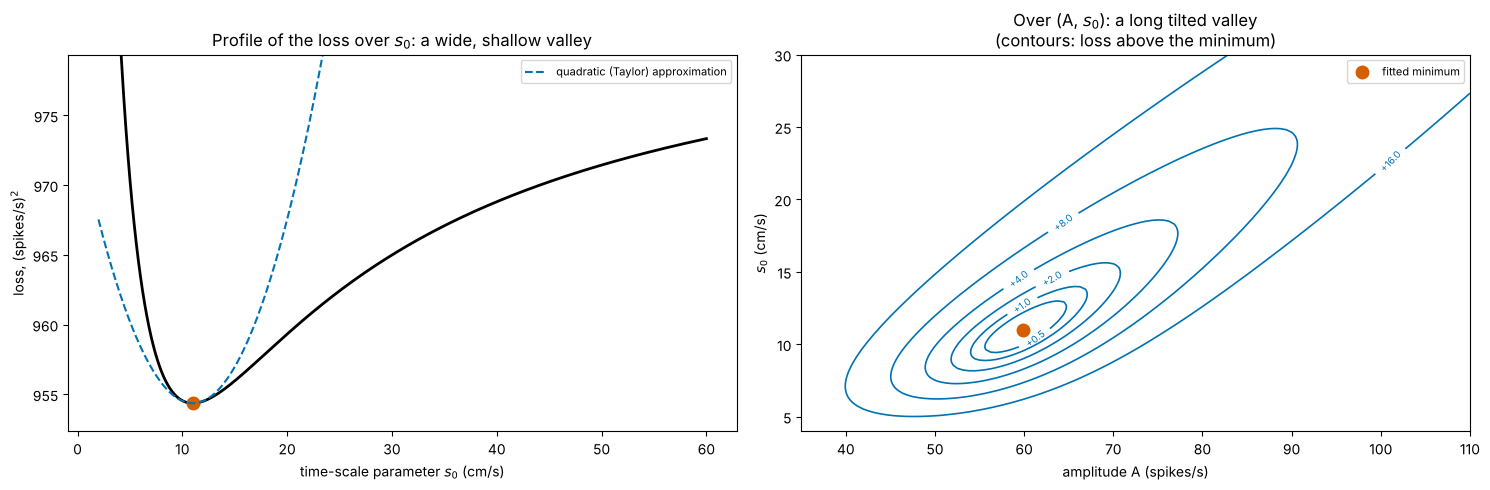

In [13]:
A_grid = np.linspace(35, 110, 121)
s0_g2 = np.linspace(4, 30, 121)
Lmap = np.zeros((s0_g2.size, A_grid.size))
for i, s0v in enumerate(s0_g2):
    g = 1 - np.exp(-s_tr / s0v)
    for j, Av in enumerate(A_grid):
        r0v = np.mean(y_tr - Av * g)                                 # best r0 for this (A, s0): least squares in one variable
        Lmap[i, j] = np.mean((y_tr - r0v - Av * g)**2)

# Hessian of the loss in (r0, A, s0) at the fitted point, by central second differences (step 1% of each parameter).
def hessian(f, p, rel=0.01):
    p = np.asarray(p, float); h = rel * np.abs(p); k = len(p); H = np.zeros((k, k))
    for a in range(k):
        for b in range(k):
            ea, eb = np.eye(k)[a] * h[a], np.eye(k)[b] * h[b]
            H[a, b] = (f(*(p + ea + eb)) - f(*(p + ea - eb)) - f(*(p - ea + eb)) + f(*(p - ea - eb))) / (4 * h[a] * h[b])
    return H
H = hessian(mse, p_hat)
ev, evec = np.linalg.eigh(H)
print("Hessian eigenvalues:", np.round(ev, 4), f" (ratio largest / smallest {ev[-1] / ev[0]:.0f})")
print("flattest direction in (r0, A, s0):", np.round(evec[:, 0], 3), "  sharpest:", np.round(evec[:, -1], 3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(s0_grid, prof, color='black', lw=2)
axes[0].plot(s0_grid[i_best], prof[i_best], 'o', color=PALETTE[1], ms=9)
axes[0].plot(s0_grid, prof.min() + 0.5 * curv * (s0_grid - s0_grid[i_best])**2, color=PALETTE[0], ls='--', label='quadratic (Taylor) approximation')
axes[0].set_ylim(prof.min() - 2, prof.min() + 25); axes[0].set_xlabel('time-scale parameter $s_0$ (cm/s)'); axes[0].set_ylabel('loss, (spikes/s)$^2$')
axes[0].set_title('Profile of the loss over $s_0$: a wide, shallow valley'); axes[0].legend(fontsize=8)
levels = Lmap.min() + np.array([0.5, 1, 2, 4, 8, 16])
cs = axes[1].contour(A_grid, s0_g2, Lmap, levels=levels, colors=[PALETTE[0]], linewidths=1.2)
axes[1].clabel(cs, fmt=lambda v: f'+{v - Lmap.min():.1f}', fontsize=7)
axes[1].plot(p_hat[1], p_hat[2], 'o', color=PALETTE[1], ms=9, label='fitted minimum')
axes[1].set_xlabel('amplitude A (spikes/s)'); axes[1].set_ylabel('$s_0$ (cm/s)')
axes[1].set_title('Over (A, $s_0$): a long tilted valley\n(contours: loss above the minimum)'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The profile over $s_0$ is a wide, shallow valley: moving $s_0$ from 11 to 20 cm/s raises the loss by only about half a percent. The quadratic approximation matches it only near the bottom; beyond about 20 cm/s the profile bends **downwards** (it is not convex) and flattens towards a plateau. Over $(A, s_0)$ the valley is long and **tilted**: a larger amplitude with a larger $s_0$ (a curve that rises more slowly towards a higher ceiling) fits almost as well as the best fit. That is the trade-off Lesson 8 predicted. Within the speeds actually observed, the two parameters compensate for each other. The Hessian's eigenvalues differ by a factor of about 100.

### What curvature says about uncertainty

For a least-squares fit, the curvature of the loss converts directly into an **estimate of how well each parameter is determined** (the details belong to Lessons 17–20). With $n$ data points and residual variance $\hat\sigma^2$, the approximate covariance of the parameter estimates is

$$\operatorname{Cov}(\hat{\boldsymbol\theta}) \approx \frac{2\hat\sigma^2}{n}\,\mathbf{H}^{-1}$$

for $\mathbf{H}$ the Hessian of the **mean** squared error. Flat directions (small eigenvalues of $\mathbf{H}$) are large eigenvalues of $\mathbf{H}^{-1}$: large uncertainty. Parameters that trade off have **correlated** estimates. `curve_fit` returns exactly this covariance. Is it right? We can check by fitting the model separately to 8 consecutive chunks of the training half and looking at how much the estimates vary.

standard errors from curvature  (r0, A, s0): [0.7  2.24 0.87]    curve_fit's: [0.73 2.37 0.95]
correlation of the A and s0 estimates implied by curvature: 0.77
chunk estimates (r0, A, s0):
 [[54.1 51.2 15.3]
 [50.3 53.  10.7]
 [47.9 51.7 10.9]
 [46.9 54.5 10.6]
 [43.4 60.6  9.7]
 [39.4 77.9 13.4]
 [39.8 58.3  8.2]
 [39.4 85.6 16.4]]
standard errors implied by the chunks: [1.96 4.61 1.01] ;  correlation of A and s0 across chunks 0.55


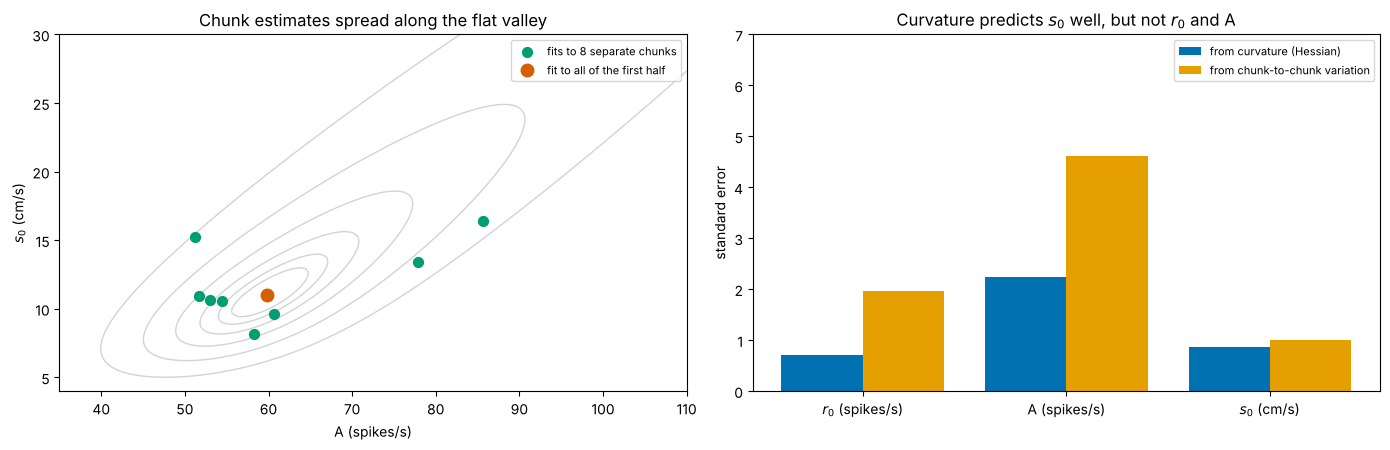

In [14]:
n_tr = s_tr.size
sigma2 = mse(*p_hat)                                                 # residual variance (spikes/s)^2
cov_H = 2 * sigma2 / n_tr * np.linalg.inv(H)
se_H = np.sqrt(np.diag(cov_H))
corr_H = cov_H / np.outer(se_H, se_H)
_, cov_cf = curve_fit(model, s_tr, y_tr, p0=p_hat)
print("standard errors from curvature  (r0, A, s0):", np.round(se_H, 2), "   curve_fit's:", np.round(np.sqrt(np.diag(cov_cf)), 2))
print(f"correlation of the A and s0 estimates implied by curvature: {corr_H[1, 2]:.2f}")

K = 8
chunks = np.array_split(np.arange(n_tr), K)
est = np.array([curve_fit(model, s_tr[c], y_tr[c], p0=p_hat, maxfev=20000)[0] for c in chunks])
spread = est.std(axis=0, ddof=1) / np.sqrt(K)                        # standard error of the full-data estimate implied by chunk-to-chunk variation
print("chunk estimates (r0, A, s0):\n", np.round(est, 1))
print("standard errors implied by the chunks:", np.round(spread, 2), f";  correlation of A and s0 across chunks {np.corrcoef(est[:, 1], est[:, 2])[0, 1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].contour(A_grid, s0_g2, Lmap, levels=levels, colors=['lightgrey'], linewidths=1)
axes[0].scatter(est[:, 1], est[:, 2], color=PALETTE[2], s=50, zorder=3, label='fits to 8 separate chunks')
axes[0].plot(p_hat[1], p_hat[2], 'o', color=PALETTE[1], ms=9, label='fit to all of the first half')
axes[0].set_xlabel('A (spikes/s)'); axes[0].set_ylabel('$s_0$ (cm/s)'); axes[0].set_title('Chunk estimates spread along the flat valley'); axes[0].legend(fontsize=8)
xpos = np.arange(3)
axes[1].bar(xpos - 0.2, se_H, 0.4, color=PALETTE[0], label='from curvature (Hessian)')
axes[1].bar(xpos + 0.2, spread, 0.4, color=PALETTE[4], label='from chunk-to-chunk variation')
axes[1].set_xticks(xpos); axes[1].set_xticklabels(['$r_0$ (spikes/s)', 'A (spikes/s)', '$s_0$ (cm/s)'])
axes[1].set_ylim(0, 7); axes[1].set_ylabel('standard error'); axes[1].set_title('Curvature predicts $s_0$ well, but not $r_0$ and A'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**
- **The fitting problem is non-convex** in $s_0$, but its landscape has a single, very shallow valley.
- **The valley is long and tilted.** Amplitude and timescale trade off: larger $A$ with larger $s_0$ fits almost as well. Their estimates are strongly correlated (about 0.8 by curvature, about 0.55 across chunks). The chunk fits lie along the flat valley, just as the curvature predicts.
- **Curvature predicts $s_0$'s uncertainty well** (about 1 cm/s by both methods).
- **For $r_0$ and $A$ it is too optimistic, by a factor of 2–3.** The curvature formula assumes independent, identically distributed noise around a fixed model. Here the neuron's baseline drifts across the session (the chunk estimates of $r_0$ fall from about 54 to 39 spikes/s, the drift found in Lesson 8), and neighbouring 50 ms bins are correlated. Neither of these is visible in the shape of the loss at its minimum.

The flat directions of a loss landscape are where data say little. Curvature tells you which directions those are, but only under its assumptions. An independent check, such as refitting on separate chunks, tells you whether to believe it.

**Limitations.** One neuron, one model; second derivatives estimated by finite differences with a fixed relative step; chunks are consecutive, so they mix sampling noise with drift; the uncertainty formula is an approximation that Lessons 17–20 develop properly.

# **Part 7: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Critical points of an energy | attractor networks: stored memories are minima (Hopfield), decisions settle into one of two wells | equilibrium of training dynamics; stationary points of a loss |
| Stability from curvature | stable states have positive curvature; unstable ones negative (Lessons 6, 23: eigenvalues of the Jacobian) | minima versus saddles in high-dimensional losses |
| Taylor approximation | linearising nonlinear neuron models around a resting state (Lesson 23) | Newton and quasi-Newton optimisers; second-order analysis of training |
| Convexity | least-squares encoding/decoding models and GLMs are convex: reliable fits | linear and logistic regression, SVMs; deep networks are non-convex |
| Local minima, multiple starts | fitting biophysical models (Hodgkin-Huxley parameters) needs many starts or global methods | random restarts, ensembles; flat minima often generalise well |
| Flat directions, trade-offs | "sloppy" models: many parameter combinations fit neural data equally well; degeneracy of neuron and circuit parameters | ill-conditioning, slow training; sharpness of minima |
| Regularisation | ridge-regularised receptive-field and decoding models | weight decay, ridge, priors (Lesson 19) |

**Degeneracy in neural circuits.** Experiments on the crustacean stomatogastric ganglion found that very different combinations of ion-channel conductances produce nearly identical rhythmic activity (Prinz, Bucher and Marder, 2004). In the language of this lesson, the "loss" measuring how well a model neuron reproduces the rhythm has long, flat valleys in conductance space. Biology may exploit this flatness: many parameter settings work, so circuits can be robust to changes in individual components.

# **Part 8: Summary and Lesson 12 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Critical point | $f'(x^*) = 0$ | also check endpoints and points where $f'$ does not exist |
| First-derivative test | sign of $f'$ changes $- \to +$ / $+ \to -$ / not at all | minimum / maximum / neither |
| Second derivative | $f'' > 0$ bends up, $< 0$ bends down | second-derivative test; units per input unit squared |
| Inflection point | $f''$ changes sign | the steepest point of $f$ (largest $|f'|$) |
| Taylor | $f(x + h) \approx f + f'h + \frac12 f''h^2 + \dots$ | each term adds a power of $h$ of accuracy; valleys look like parabolas |
| Newton's method | $x \leftarrow x - f'/f''$ | very fast near a minimum, but finds any critical point |
| Convexity | chords above the graph; $f'' \ge 0$ | every local minimum is global; least squares is convex |
| Non-convexity | several valleys | downhill finds a local minimum that depends on the start |
| Hessian | matrix of second derivatives | eigenvectors: sharp and flat directions; eigenvalues: curvatures |
| Flat directions | small curvature | parameters trade off; large, correlated uncertainty |
| Regularisation | $+\frac{\lambda}{2}\lVert\boldsymbol\theta\rVert^2$ adds $\lambda$ to every curvature | sharper, unique minimum; small bias |

**Lesson 12 — One-dimensional gradient descent.** Knowing where the bottom is does not say how to get there. Gradient descent walks downhill one step at a time, $\theta \leftarrow \theta - \eta f'(\theta)$. Curvature from this lesson decides how large a step $\eta$ can be before the walk overshoots and diverges.